In [1]:
from itertools import islice
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def uniform_triangle(u, v):
    while True:
        s = np.random.uniform()
        t = np.random.uniform()
        in_triangle = s + t <= 1
        p = s * u + t * v if in_triangle else (1 - s) * u + (1 - t) * v
        yield p


triangle_set1 = [
    np.array([[0, 0], [0.5, 0.5], [0, 0.5]]),
    np.array([[0.5, 0.5], [0, 0.5], [0, 1.0]]),
]
triangle_set2 = [np.concatenate((a[:, 1:2], a[:, 0:1]), axis=1) for a in triangle_set1]

triangle_set = triangle_set1 + triangle_set2

[[0.16666667 0.33333333]
 [0.16666667 0.66666667]
 [0.33333333 0.16666667]
 [0.66666667 0.16666667]]
[[0.        ]
 [0.33333333]
 [0.66666667]
 [1.        ]]


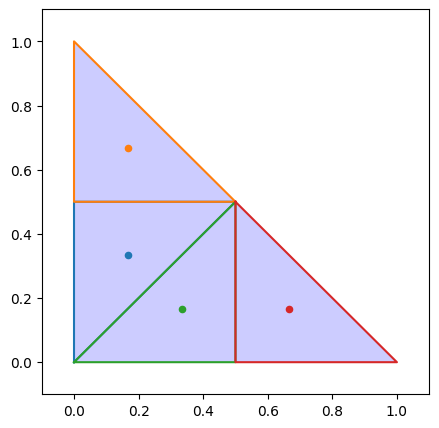

In [2]:
np.random.seed(42)

fig, ax = plt.subplots(figsize=(5, 5))
point_total = []

for triangle in triangle_set:
    # draw the triangle
    x_coords, y_coords = zip(*triangle)
    # Close the triangle by adding the first vertex at the end
    x_coords += (x_coords[0],)
    y_coords += (y_coords[0],)

    # Create the plot
    ax.plot(x_coords, y_coords)  # 'o' for circle markers at the vertices
    ax.fill(
        x_coords, y_coords, "b", alpha=0.2
    )  # Fill the triangle with a blue color and some transparency

    it = uniform_triangle(
        triangle[1] - triangle[0],
        triangle[2] - triangle[0],
    )
    points = triangle.mean(axis=0).reshape(-1, 2)

    ax.scatter(points[:, 0], points[:, 1], s=20)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)

    point_total.append(points)
point_total = np.concatenate(point_total)

array = np.linspace(0, 1, 5)

mean_values = np.linspace(0, 1, 4).reshape(-1, 1)
print(point_total)
print(mean_values)

In [3]:
metal_combo = np.array(
    [
        ["Co", "Cd"],
        ["Cu", "Mn"],
        ["Ni", "Cd"],
        ["Co", "Mn"],
        ["Cu", "Cd"],
        ["Co", "Al"],
        ["Co", "Fe"],
    ]
)

np.random.seed(42)
candidates_total = []
for metal_combo_temp in metal_combo:
    a_temp = point_total.copy()
    b_temp = mean_values.copy()
    c_temp = mean_values.copy()
    np.random.shuffle(a_temp)
    np.random.shuffle(b_temp)
    np.random.shuffle(c_temp)
    candidates = np.around(
        np.concatenate((a_temp * 9.5 + 0.5, b_temp * 5, c_temp * 5), axis=1), 2
    )

    water = (20 - candidates.sum(axis=1)).reshape(-1, 1)
    candidates = np.concatenate((candidates, water), axis=1)
    candidates_total.append(candidates)
    print(metal_combo_temp)
    print(candidates)

['Co' 'Cd']
[[ 2.08  6.83  1.67  5.    4.42]
 [ 6.83  2.08  5.    0.    6.09]
 [ 2.08  3.67  0.    1.67 12.58]
 [ 3.67  2.08  3.33  3.33  7.59]]
['Cu' 'Mn']
[[ 2.08  6.83  3.33  0.    7.76]
 [ 2.08  3.67  1.67  1.67 10.91]
 [ 6.83  2.08  0.    3.33  7.76]
 [ 3.67  2.08  5.    5.    4.25]]
['Ni' 'Cd']
[[6.83 2.08 0.   5.   6.09]
 [3.67 2.08 3.33 3.33 7.59]
 [2.08 6.83 1.67 0.   9.42]
 [2.08 3.67 5.   1.67 7.58]]
['Co' 'Mn']
[[ 2.08  3.67  1.67  1.67 10.91]
 [ 3.67  2.08  3.33  0.   10.92]
 [ 2.08  6.83  5.    5.    1.09]
 [ 6.83  2.08  0.    3.33  7.76]]
['Cu' 'Cd']
[[ 2.08  3.67  0.    0.   14.25]
 [ 6.83  2.08  5.    1.67  4.42]
 [ 3.67  2.08  3.33  5.    5.92]
 [ 2.08  6.83  1.67  3.33  6.09]]
['Co' 'Al']
[[ 2.08  6.83  1.67  1.67  7.75]
 [ 3.67  2.08  5.    3.33  5.92]
 [ 2.08  3.67  3.33  5.    5.92]
 [ 6.83  2.08  0.    0.   11.09]]
['Co' 'Fe']
[[ 3.67  2.08  0.    3.33 10.92]
 [ 6.83  2.08  3.33  5.    2.76]
 [ 2.08  3.67  5.    1.67  7.58]
 [ 2.08  6.83  1.67  0.    9.42]]


In [4]:
_all_candidates = []
# export the json file
# set a repeat experiment as a reference
repeat_exp = pd.DataFrame(
    {
        "substance1": ["Co"],
        "volume1": [4.0],
        "substance2": ["Mn"],
        "volume2": [4.0],
        "substance3": ["Na3Cit"],
        "volume3": [3.0],
        "substance4": ["H3BO3"],
        "volume4": [4.0],
        "substance5": ["water"],
        "volume5": [5.0],
        
        "syn_completed": ["None"],
        "storage_location": ["None"],
        "in_storage": ["None"],
        "cat_completed": ["None"], 
        
        "lsv_overpotential_-0.01": ["None"],
        "lsv_overpotential_-0.02": ["None"],
        "lsv_overpotential_-0.03": ["None"],
        "lsv_overpotential_-0.04": ["None"],
        "lsv_overpotential_-0.05": ["None"],
    }
)

repeat_index = [0]

for candidate_index in range(len(candidates_total[0])):
    # write the new candidates to the excel for the closed-loop discovery
    exp_data_out = {}
    exp_data_out["substance1"] = []
    exp_data_out["volume1"] = []
    exp_data_out["substance2"] = []
    exp_data_out["volume2"] = []
    exp_data_out["substance3"] = []
    exp_data_out["volume3"] = []
    exp_data_out["substance4"] = []
    exp_data_out["volume4"] = []
    exp_data_out["substance5"] = []
    exp_data_out["volume5"] = []

    exp_data_out["syn_completed"] = []
    exp_data_out["storage_location"] = []
    exp_data_out["in_storage"] = []

    exp_data_out["cat_completed"] = []
    exp_data_out["lsv_overpotential_-0.01"] = []
    exp_data_out["lsv_overpotential_-0.02"] = []
    exp_data_out["lsv_overpotential_-0.03"] = []
    exp_data_out["lsv_overpotential_-0.04"] = []
    exp_data_out["lsv_overpotential_-0.05"] = []

    exp_data_out = pd.DataFrame(exp_data_out)

    for metal_index in range(len(metal_combo)):
        if len(exp_data_out) in repeat_index:
            exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)

        temp = pd.DataFrame(
            {
                "substance1": [metal_combo[metal_index][0]],
                "volume1": [candidates_total[metal_index][candidate_index][0]],
                "substance2": [metal_combo[metal_index][1]],
                "volume2": [candidates_total[metal_index][candidate_index][1]],
                "substance3": "Na3Cit",
                "volume3": [candidates_total[metal_index][candidate_index][2]],
                "substance4": "H3BO3",
                "volume4": [candidates_total[metal_index][candidate_index][3]],
                "substance5": "water",
                "volume5": [candidates_total[metal_index][candidate_index][4]],
                "syn_completed": ["None"],
                "storage_location": ["None"],
                "in_storage": ["None"],
                "cat_completed": ["None"], 
                "lsv_overpotential_-0.01": ["None"],
                "lsv_overpotential_-0.02": ["None"],
                "lsv_overpotential_-0.03": ["None"],
                "lsv_overpotential_-0.04": ["None"],
                "lsv_overpotential_-0.05": ["None"],
            }
        )

        for repeat in range(1):
            exp_data_out = pd.concat((exp_data_out, temp), ignore_index=True)
    if len(exp_data_out) in repeat_index:
        exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)
    display(exp_data_out)
    _all_candidates.append(exp_data_out)
    exp_data_out.to_json(f"./initial_sampling_{candidate_index}.json")

,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,2.08,Cd,6.83,Na3Cit,1.67,H3BO3,5.00,water,4.42,None,None,None,None,None,None,None,None,None
2,Cu,2.08,Mn,6.83,Na3Cit,3.33,H3BO3,0.00,water,7.76,None,None,None,None,None,None,None,None,None
3,Ni,6.83,Cd,2.08,Na3Cit,0.00,H3BO3,5.00,water,6.09,None,None,None,None,None,None,None,None,None
4,Co,2.08,Mn,3.67,Na3Cit,1.67,H3BO3,1.67,water,10.91,None,None,None,None,None,None,None,None,None
5,Cu,2.08,Cd,3.67,Na3Cit,0.00,H3BO3,0.00,water,14.25,None,None,None,None,None,None,None,None,None
6,Co,2.08,Al,6.83,Na3Cit,1.67,H3BO3,1.67,water,7.75,None,None,None,None,None,None,None,None,None
7,Co,3.67,Fe,2.08,Na3Cit,0.00,H3BO3,3.33,water,10.92,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,6.83,Cd,2.08,Na3Cit,5.00,H3BO3,0.00,water,6.09,None,None,None,None,None,None,None,None,None
2,Cu,2.08,Mn,3.67,Na3Cit,1.67,H3BO3,1.67,water,10.91,None,None,None,None,None,None,None,None,None
3,Ni,3.67,Cd,2.08,Na3Cit,3.33,H3BO3,3.33,water,7.59,None,None,None,None,None,None,None,None,None
4,Co,3.67,Mn,2.08,Na3Cit,3.33,H3BO3,0.00,water,10.92,None,None,None,None,None,None,None,None,None
5,Cu,6.83,Cd,2.08,Na3Cit,5.00,H3BO3,1.67,water,4.42,None,None,None,None,None,None,None,None,None
6,Co,3.67,Al,2.08,Na3Cit,5.00,H3BO3,3.33,water,5.92,None,None,None,None,None,None,None,None,None
7,Co,6.83,Fe,2.08,Na3Cit,3.33,H3BO3,5.00,water,2.76,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,2.08,Cd,3.67,Na3Cit,0.00,H3BO3,1.67,water,12.58,None,None,None,None,None,None,None,None,None
2,Cu,6.83,Mn,2.08,Na3Cit,0.00,H3BO3,3.33,water,7.76,None,None,None,None,None,None,None,None,None
3,Ni,2.08,Cd,6.83,Na3Cit,1.67,H3BO3,0.00,water,9.42,None,None,None,None,None,None,None,None,None
4,Co,2.08,Mn,6.83,Na3Cit,5.00,H3BO3,5.00,water,1.09,None,None,None,None,None,None,None,None,None
5,Cu,3.67,Cd,2.08,Na3Cit,3.33,H3BO3,5.00,water,5.92,None,None,None,None,None,None,None,None,None
6,Co,2.08,Al,3.67,Na3Cit,3.33,H3BO3,5.00,water,5.92,None,None,None,None,None,None,None,None,None
7,Co,2.08,Fe,3.67,Na3Cit,5.00,H3BO3,1.67,water,7.58,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,3.67,Cd,2.08,Na3Cit,3.33,H3BO3,3.33,water,7.59,None,None,None,None,None,None,None,None,None
2,Cu,3.67,Mn,2.08,Na3Cit,5.00,H3BO3,5.00,water,4.25,None,None,None,None,None,None,None,None,None
3,Ni,2.08,Cd,3.67,Na3Cit,5.00,H3BO3,1.67,water,7.58,None,None,None,None,None,None,None,None,None
4,Co,6.83,Mn,2.08,Na3Cit,0.00,H3BO3,3.33,water,7.76,None,None,None,None,None,None,None,None,None
5,Cu,2.08,Cd,6.83,Na3Cit,1.67,H3BO3,3.33,water,6.09,None,None,None,None,None,None,None,None,None
6,Co,6.83,Al,2.08,Na3Cit,0.00,H3BO3,0.00,water,11.09,None,None,None,None,None,None,None,None,None
7,Co,2.08,Fe,6.83,Na3Cit,1.67,H3BO3,0.00,water,9.42,None,None,None,None,None,None,None,None,None


In [5]:
pd.concat(_all_candidates, ignore_index=True).to_json(f"./initial_sampling_all.json")